### **Лабораторна 5. Донавчання моделей (Fine-Tuning)**

In [ ]:
!pip install -q "transformers>=4.55.0" "jsonschema" "trl>=1.17" "peft" "bitsandbytes" "datasets" "accelerate" "huggingface_hub"
!pip uninstall -q -y torchao

In [ ]:
import gc
import json
import math
import re
import time
from pprint import pprint
import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_dataset
from jsonschema import validate
from peft import LoraConfig
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, EarlyStoppingCallback, set_seed
from trl import SFTConfig, SFTTrainer
assert torch.cuda.is_available(), "Для цього ноутбука потрібна GPU"
print(f"GPU: {torch.cuda.get_device_name()}")
print(f"Памʼять GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4
Памʼять GPU: 15.6 GB


## Задача та обґрунтування підходу
### Суть задачі та практичне застосування
У цьому проєкті розв'язується задача **генерації структурованого JSON за заданою JSON-схемою**: модель отримує формальну схему та короткий запит природною мовою (що саме потрібно повернути) і має відповісти JSON-об'єктом, який проходить валідацію за цією схемою.

**Цільовий користувач:** бекенд-розробники та інженери автоматизації, які вбудовують LLM у програмні системи як компонент, від якого наступна ланка конвеєра очікує машинозчитуваний результат.

**Практичне використання:** відповідь моделі напряму десеріалізується кодом і валідується за схемою (наприклад, структуровані відповіді для API, генерація тестових чи демонстраційних наборів даних за схемою). У такій постановці модель відповідає за **формат і відповідність схемі**, а не за достовірність значень: у датасеті значення вигадані (див. «Модель і дані»), тому для витягування реальних фактів із довільного тексту потрібні інший набір даних і інша метрика.

**Вхідні дані:** JSON Schema і короткий текстовий запит англійською мовою.

**Вихідні дані:** лише JSON-об'єкт (або масив), що проходить валідацію за схемою, без пояснень, вступних фраз і обгорток Markdown. Бажана частка відповідей, що проходять валідацію, - 100%; фактично досягнуту частку виміряно нижче.

**Чому потрібне донавчання, а не промпт:** навіть з явною інструкцією в системному промпті («лише валідний JSON, без пояснень і Markdown») базова модель Qwen3-1.7B дала JSON, що проходить валідацію за схемою, лише у 68% тестових прикладів. Імовірна основна причина - багатослівне форматування відповіді (відступи й переноси рядків): довгі відповіді впираються в ліміт довжини й обриваються (див. аналіз помилок). У нашому експерименті промпт цього не усунув, тоді як LoRA-донавчання на прикладах «схема → компактний JSON» змінює сам стиль відповіді.

**Чому не підходить RAG:** RAG потрібна для отримання зовнішніх фактів із бази знань, а в нашому випадку вся необхідна інформація (JSON-схема і запит) вже міститься у запиті користувача.

### Модель і дані

**Датасет:** [ChristianAzinn/json-training](https://huggingface.co/datasets/ChristianAzinn/json-training) - синтетичний англомовний набір для навчання генерації структурованого JSON за схемою. Згенерований LLM: переважно Llama 3.1 8B, близько 2000 прикладів - Claude 3.5 Sonnet.

**Ліцензія:** Apache License 2.0 - дозволяє вільно використовувати, модифікувати та поширювати датасет за умови збереження повідомлення про авторські права та копії самої ліцензії при розповсюдженні похідних матеріалів.

**Обсяг і формат:** 20 644 записи у форматі JSON з полями query (текстовий запит без структурних компонентів), schema (JSON-схема) і response (приклад відповіді, що відповідає схемі). Приклади наведено у виводі наступної клітинки.

**Підготовка:** перемішування, видалення дублікатів пар (schema, query) і записів, response яких не проходить валідацію за власною схемою; відібрано 3 500 записів; response приведено до компактного JSON; формат чату: system → user (JSON Schema: … Text: …) → assistant.

**Поділ:** train - 2 450 (2 395 після відсікання прикладів довших за 1024 токени); validation - 300 (під час навчання використано перші 100); test - 300. Діапазони не перетинаються, тестові приклади в навчання не потрапляють.

**Важливе обмеження датасету:** значення в response вигадані LLM, а query не містить тексту, з якого їх можна було б витягти. Тому це задача генерації за схемою, а не витягування фактів.

In [ ]:
source_ds = load_dataset("ChristianAzinn/json-training", split="train")
print(source_ds)

for sample in source_ds.shuffle(seed=101).select(range(2)):
    print("-" * 40)
    for field_name, field_val in sample.items():
        print(f"[{field_name}]: {str(field_val)[:280]}")

README.md:   0%|          | 0.00/1.45k [00:00<?, ?B/s]

json-training-2.json: reconstructing file:   0%|          |  0.00B / 22.7MB            

json-training-2.json: downloading bytes:           |  0.00B            

json-training.json: reconstructing file:   0%|          |  0.00B / 22.1MB            

json-training.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/20644 [00:00<?, ? examples/s]

Dataset({
    features: ['query', 'schema', 'response'],
    num_rows: 20644
})
----------------------------------------
[query]: Get the family members of a person with their relationships and birth dates.
[schema]: {
  "type": "object",
  "properties": {
    "family_members": {
      "type": "array",
      "items": {
        "type": "object",
        "properties": {
          "name": {"type": "string"},
          "relationship": {"type": "string"},
          "birth_date": {"type": "string",
[response]: {
  "family_members": [
    {"name": "John", "relationship": "father", "birth_date": "1990-01-01"},
    {"name": "Emily", "relationship": "mother", "birth_date": "1985-06-15"},
    {"name": "Alice", "relationship": "sister", "birth_date": "2002-03-20"}
  ]
}
----------------------------------------
[query]: Retrieve the ancestors of a person named John Smith, including their names, birth dates, and marriage status.
[schema]: {
  "type": "object",
  "properties": {
    "ancestors": {
  

In [ ]:
EXTRACTION_SYSTEM_PROMPT = (
    "Extract information from the text and format it strictly as a JSON object "
    "conforming to the provided JSON Schema. Return only valid JSON, without explanations or Markdown."
)

def strip_markdown_fences(raw_text: str) -> str:
    cleaned = raw_text.strip()
    match = re.fullmatch(r"```(?:json)?\s*\n?(.*?)\n?```", cleaned, flags=re.IGNORECASE | re.DOTALL)
    return match.group(1).strip() if match else cleaned

def canonicalize_if_valid(json_payload: str, schema_payload: str):
    """Повертає нормалізований JSON-рядок, якщо він валідний і відповідає схемі, інакше None."""
    try:
        parsed_obj = json.loads(strip_markdown_fences(json_payload))
        parsed_schema = json.loads(schema_payload) if isinstance(schema_payload, str) else schema_payload
        if not isinstance(parsed_obj, (dict, list)) or not isinstance(parsed_schema, dict):
            return None
        validate(instance=parsed_obj, schema=parsed_schema)
        return json.dumps(parsed_obj, sort_keys=True, ensure_ascii=False)
    except Exception:
        return None

available_cols = source_ds.column_names

def unpack_record(item: dict) -> tuple[str, str, str]:
    if {"schema", "query", "response"}.issubset(available_cols):
        return str(item["schema"]), str(item["query"]), str(item["response"])
    if {"schema", "input", "output"}.issubset(available_cols):
        return str(item["schema"]), str(item["input"]), str(item["output"])
    if {"json_schema", "text", "json"}.issubset(available_cols):
        return str(item["json_schema"]), str(item["text"]), str(item["json"])
    raise KeyError(f"Неизвестные колонки датасета: {available_cols}")

filtered_ids = []
unique_pairs = set()
randomized_ds = source_ds.shuffle(seed=101)

for idx, item in enumerate(randomized_ds):
    schema_txt, user_txt, target_txt = unpack_record(item)
    pair_key = (schema_txt.strip(), user_txt.strip())
    if pair_key in unique_pairs:
        continue
    if canonicalize_if_valid(target_txt, schema_txt) is not None:
        unique_pairs.add(pair_key)
        filtered_ids.append(idx)
    if len(filtered_ids) >= 3500:
        break

verified_ds = randomized_ds.select(filtered_ids)
print(f"Кількість перевірених унікальних записів: {len(verified_ds)}")

def format_chat_record(item: dict) -> dict:
    schema_txt, user_txt, target_txt = unpack_record(item)
    normalized_target = json.dumps(json.loads(target_txt.strip()), ensure_ascii=False)
    return {
        "messages": [
            {"role": "system", "content": EXTRACTION_SYSTEM_PROMPT},
            {"role": "user", "content": f"JSON Schema:\n{schema_txt.strip()}\n\nText:\n{user_txt.strip()}"},
            {"role": "assistant", "content": normalized_target},
        ],
        "json_schema": schema_txt.strip(),
        "chat_template_kwargs": {"enable_thinking": False},
    }

prepared_ds = verified_ds.map(format_chat_record, remove_columns=verified_ds.column_names)

TRAIN_SIZE = min(2500, int(len(prepared_ds) * 0.7))
VAL_SIZE = min(300, int(len(prepared_ds) * 0.1))
TEST_SIZE = min(300, len(prepared_ds) - TRAIN_SIZE - VAL_SIZE)

ds_train = prepared_ds.select(range(TRAIN_SIZE))
ds_val = prepared_ds.select(range(TRAIN_SIZE, TRAIN_SIZE + VAL_SIZE))
ds_test = prepared_ds.select(range(TRAIN_SIZE + VAL_SIZE, TRAIN_SIZE + VAL_SIZE + TEST_SIZE))

print(f"Розбиття вибірки -> Train: {len(ds_train)} | Val: {len(ds_val)} | Test: {len(ds_test)}")
pprint(ds_train[0]["messages"])

Кількість перевірених унікальних записів: 3500


Map:   0%|          | 0/3500 [00:00<?, ? examples/s]

Розбиття вибірки -> Train: 2450 | Val: 300 | Test: 300
[{'content': 'Extract information from the text and format it strictly as a '
             'JSON object conforming to the provided JSON Schema. Return only '
             'valid JSON, without explanations or Markdown.',
  'role': 'system'},
 {'content': 'JSON Schema:\n'
             '{\n'
             '  "type": "object",\n'
             '  "properties": {\n'
             '    "family_members": {\n'
             '      "type": "array",\n'
             '      "items": {\n'
             '        "type": "object",\n'
             '        "properties": {\n'
             '          "name": {"type": "string"},\n'
             '          "relationship": {"type": "string"},\n'
             '          "birth_date": {"type": "string", "format": "date"}\n'
             '        },\n'
             '        "required": ["name", "relationship", "birth_date"]\n'
             '      }\n'
             '    }\n'
             '  },\n'
             '

**Модель:** [Qwen/Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B)

Модель має 1.7 млрд параметрів, легко поміщається у відеопам'ять T4 GPU (16 GB) у форматі float16 та підтримує сучасний шаблон діалогу з можливістю вимкнення режиму роздумів. Обрано інструктивну версію Qwen3-1.7B, щоб коректно оцінити її базову здатність дотримуватися JSON-схем за промптом до донавчання.

In [ ]:
BASE_MODEL_ID = "Qwen/Qwen3-1.7B"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)
llm_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID,
    dtype=torch.float16,
    device_map="auto",
)
print(f"Модель {BASE_MODEL_ID} успішно завантажена на {llm_model.device}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель Qwen/Qwen3-1.7B успішно завантажена на cuda:0


### Метрика й результат до донавчання

**Обґрунтування вибору метрик:** класичні текстові метрики (BLEU, ROUGE або посимвольна точність) не підходять для оцінювання JSON, оскільки порядок ключів або форматування пробілів не впливають на валідність даних, тоді як одна зайва кома повністю ламає парсер. Тому використано три прикладні метрики:

**JSON Syntax Rate** - частка відповідей, які успішно розбираються стандартним парсером json.loads() без синтаксичних помилок.

**Schema Compliance** - частка відповідей, які не лише є синтаксично коректним JSON, а й проходять повну валідацію за переданою JSON-схемою. Це головна продуктова метрика.

**Canonical Exact Match** - частка відповідей, які після парсингу та сортування ключів збігаються з еталонним JSON. Це допоміжна метрика, і в цій постановці вона неінформативна: EM має сенс, коли для входу існує єдина правильна відповідь. Тут еталон - лише один із багатьох допустимих JSON (значення в датасеті вигадані LLM, а запит їх не містить), тож збіг практично неможливий для будь-якої моделі, і метрика не розрізняє базову та донавчену модель (0.00% в обох випадках). Її наведено для повноти.

**Умови оцінювання:** тестовий набір - 300 прикладів; системний промпт EXTRACTION_SYSTEM_PROMPT з вимогою повертати лише валідний JSON без пояснень і Markdown; режим міркування вимкнено; жадібне декодування, max_new_tokens=384. Для порівняння «до/після» використано той самий набір, ті самі приклади й ті самі налаштування генерації.

In [ ]:
@torch.inference_mode()
def run_batch_inference(model, tokenizer, queries: list[str], sys_prompt: str, max_tokens: int = 384) -> list[str]:
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    saved_padding_side = tokenizer.padding_side
    was_in_train_mode = model.training
    try:
        model.eval()
        tokenizer.padding_side = "left"
        formatted_prompts = [
            tokenizer.apply_chat_template(
                [{"role": "system", "content": sys_prompt}, {"role": "user", "content": q}],
                tokenize=False,
                add_generation_prompt=True,
                enable_thinking=False,
            )
            for q in queries
        ]
        encoded_batch = tokenizer(formatted_prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        generated_ids = model.generate(
            **encoded_batch,
            max_new_tokens=max_tokens,
            do_sample=False,
            num_beams=1,
            use_cache=True,
            pad_token_id=tokenizer.pad_token_id,
        )
        completion_ids = generated_ids[:, encoded_batch["input_ids"].shape[1]:]
        return [out.strip() for out in tokenizer.batch_decode(completion_ids, skip_special_tokens=True)]
    finally:
        tokenizer.padding_side = saved_padding_side
        model.train(was_in_train_mode)

def score_json_outputs(preds: list[str], refs: list[str], schemas: list[str]) -> tuple[dict, pd.DataFrame]:
    audit_log = []
    valid_syntax_count = valid_schema_count = exact_count = 0
    n_samples = len(refs)

    for pred_raw, ref_raw, schema_raw in zip(preds, refs, schemas):
        stripped_pred = strip_markdown_fences(pred_raw)
        is_syntax_valid = False
        is_schema_valid = False
        canonical_pred = None
        canonical_ref = json.dumps(json.loads(ref_raw), sort_keys=True, ensure_ascii=False)

        try:
            obj = json.loads(stripped_pred)
            if isinstance(obj, (dict, list)):
                is_syntax_valid = True
                canonical_pred = json.dumps(obj, sort_keys=True, ensure_ascii=False)
                validate(instance=obj, schema=json.loads(schema_raw))
                is_schema_valid = True
        except Exception:
            pass

        is_exact = is_syntax_valid and is_schema_valid and (canonical_pred == canonical_ref)
        valid_syntax_count += int(is_syntax_valid)
        valid_schema_count += int(is_schema_valid)
        exact_count += int(is_exact)

        audit_log.append({
            "reference": canonical_ref,
            "prediction": pred_raw,
            "syntax_ok": is_syntax_valid,
            "schema_ok": is_schema_valid,
            "exact_match": is_exact,
        })

    summary = {
        "JSON Syntax Rate, %": 100.0 * valid_syntax_count / n_samples,
        "Schema Compliance, %": 100.0 * valid_schema_count / n_samples,
        "Canonical EM, %": 100.0 * exact_count / n_samples,
        "Тестових прикладів": n_samples,
    }
    return summary, pd.DataFrame(audit_log)

def benchmark_on_split(model, tokenizer, split_ds, sys_prompt: str, batch_sz: int = 32) -> tuple[dict, pd.DataFrame]:
    user_queries = [row["messages"][1]["content"] for row in split_ds]
    gold_answers = [row["messages"][2]["content"] for row in split_ds]
    schema_list = [row["json_schema"] for row in split_ds]
    order = sorted(range(len(user_queries)), key=lambda i: len(user_queries[i]))
    all_preds = [None] * len(user_queries)

    for offset in tqdm(range(0, len(order), batch_sz), desc="Інференс на тесті"):
        idx = order[offset : offset + batch_sz]
        outs = run_batch_inference(model, tokenizer, [user_queries[i] for i in idx], sys_prompt)
        for i, out in zip(idx, outs):
            all_preds[i] = out

    summary, details_df = score_json_outputs(all_preds, gold_answers, schema_list)
    details_df.insert(0, "prompt_input", user_queries)
    return summary, details_df
import os, pickle
BASELINE_CACHE = "baseline.pkl"
if os.path.exists(BASELINE_CACHE):
    baseline_metrics, baseline_df = pickle.load(open(BASELINE_CACHE, "rb"))
else:
    baseline_metrics, baseline_df = benchmark_on_split(llm_model, tokenizer, ds_test, EXTRACTION_SYSTEM_PROMPT)
    pickle.dump((baseline_metrics, baseline_df), open(BASELINE_CACHE, "wb"))
print(baseline_metrics)
display(baseline_df.head(7))


Інференс на тесті:   0%|          | 0/10 [00:00<?, ?it/s]

{'JSON Syntax Rate, %': 70.0, 'Schema Compliance, %': 68.0, 'Canonical EM, %': 0.0, 'Тестових прикладів': 300}


,prompt_input,reference,prediction,syntax_ok,schema_ok,exact_match
0,"JSON Schema:\n{\n ""type"": ""object"",\n ""prope...","{""games"": [{""age_range"": ""25-45"", ""duration"": ...","{\n ""games"": [\n {\n ""name"": ""Escape ...",True,True,False
1,"JSON Schema:\n{\n ""type"": ""object"",\n ""prope...","{""globalStatistics"": {""countriesWithExecutions...","{\n ""globalStatistics"": {\n ""totalExecutio...",True,True,False
2,"JSON Schema:\n{\n ""type"": ""object"",\n ""prope...","{""optimal_route"": {""end_location"": ""San Franci...","{\n ""traffic_update"": {\n ""route_id"": ""R12...",True,True,False
3,"JSON Schema:\n{\n ""type"": ""object"",\n ""prope...","{""countries"": [{""capital"": ""Ottawa"", ""name"": ""...","{\n ""countries"": [\n {\n ""name"": ""Uni...",True,True,False
4,"JSON Schema:\n{\n ""$schema"": ""http://json-sch...","[{""amino_acid_composition"": {""alanine"": 10, ""a...","[\n {\n ""protein_id"": ""protein1"",\n ""am...",True,True,False
5,"JSON Schema:\n{\n ""$schema"": ""https://json-sc...","{""confidence_interval"": [1350, 1550], ""predict...","{\n ""predicted_price"": 1250.0,\n ""confidence...",True,True,False
6,"JSON Schema:\n{\n ""type"": ""object"",\n ""prope...","{""compositionName"": ""Dance of the Elements"", ""...","{\n ""compositionName"": ""Interactive Dance Com...",False,False,False


In [ ]:
DEFAULT_ASSISTANT_PROMPT = "You are a helpful assistant. Follow the user's instructions."
general_queries = [
    "Calculate 17 multiplied by 24.",
    "Translate into Ukrainian: 'The meeting will take place tomorrow morning.'",
    "Return exactly three color names, separated by commas, without any other text.",
    "Explain the difference between a Python list and a Python tuple in two sentences.",
    "Write a Python function is_even(n) that returns True for even integers and False for odd integers. Return only the code.",
]
base_general_answers = run_batch_inference(llm_model, tokenizer, general_queries, DEFAULT_ASSISTANT_PROMPT, max_tokens=200)


### Метод донавчання й гіперпараметри

In [ ]:
set_seed(42)
tokenizer.padding_side = "right"
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

def measure_seq_tokens(record: dict) -> dict:
    tokens = tokenizer.apply_chat_template(
        record["messages"],
        tokenize=True,
        return_dict=True,
        padding=False,
        truncation=False,
        add_generation_prompt=False,
        enable_thinking=False,
    )
    return {"seq_len": len(tokens["input_ids"])}

train_sft_ds = ds_train.remove_columns(["json_schema"]).map(measure_seq_tokens)
val_sft_ds = ds_val.remove_columns(["json_schema"]).map(measure_seq_tokens)

all_lengths = pd.Series(list(train_sft_ds["seq_len"]) + list(val_sft_ds["seq_len"]))
display(all_lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame(name="Кількість токенів"))

SEQ_MAX_LEN = min(1024, max(512, math.ceil(int(all_lengths.quantile(0.99)) / 64) * 64))
train_sft_ds = train_sft_ds.filter(lambda r: r["seq_len"] <= SEQ_MAX_LEN).remove_columns(["seq_len"])
val_sft_ds = val_sft_ds.filter(lambda r: r["seq_len"] <= SEQ_MAX_LEN).remove_columns(["seq_len"])

val_sft_ds = val_sft_ds.select(range(min(100, len(val_sft_ds))))

print(f"Фінальний розмір -> Train: {len(train_sft_ds)}, Val: {len(val_sft_ds)}, SEQ_MAX_LEN: {SEQ_MAX_LEN}")

Map:   0%|          | 0/2450 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

,Кількість токенів
count,2750.000000
mean,469.895636
std,211.398389
min,111.000000
50%,417.500000
90%,712.100000
95%,878.550000
99%,1248.570000
max,2630.000000


Filter:   0%|          | 0/2450 [00:00<?, ? examples/s]

Filter:   0%|          | 0/300 [00:00<?, ? examples/s]

Фінальний розмір -> Train: 2395, Val: 100, SEQ_MAX_LEN: 1024


**Метод:** SFT з LoRA поверх Qwen3-1.7B у fp16 (адаптери на всі лінійні шари, ≈1% параметрів). Повне донавчання моделі на 1.7B параметрів не вмістилося б у T4, а задача зводиться до зміни стилю й формату відповіді, для чого LoRA достатньо.

**Learning rate = 1e-4** із косинусним затуханням (cosine) - типове значення для LoRA-матриць, що дозволяє швидко адаптувати формат генерації без руйнування базових знань моделі.

**Кількість епох = 1** - у пробному прогоні з 2 епохами (300 кроків, валідація на 290 прикладах) validation loss майже не змінювався після ~150-го кроку (0.4840 → 0.4813), тому другу епоху прибрано для економії часу; ознак перенавчання не було.

**Ефективний розмір батча = 16** (per_device_train_batch_size=1 × gradient_accumulation_steps=16) - стабільне оновлення градієнтів; батч з одного прикладу не потребує паддінгу, тож жодні токени не витрачаються марно.

**Gradient checkpointing вимкнено** - у пробному прогоні з ним пік VRAM був лише 4.4 ГБ, тож запас великий. У фінальному прогоні без checkpointing пік становив 7.67 ГБ із 15.6 ГБ, а навчання тривало 16.0 хв. Це сукупний ефект трьох змін: 1 епоха замість 2, батч 1×16 без паддінгу та вимкнений checkpointing.

**Конфігурація LoRA (r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear")** - адаптація всіх лінійних проєкцій уваги та MLP-блоків з коефіцієнтом масштабування alpha/r = 2; навчається 17.4 млн параметрів (≈1.0% від 1.74 млрд).

**Інше:** weight_decay=0.01, max_grad_norm=1.0, fp16, max_length=1024, seed=42; оцінка кожні 50 кроків із вибором найкращого чекпоінта за eval_loss.

**assistant_only_loss=True** - градієнти обчислюються виключно на токенах цільового JSON, не витрачаючи ємність адаптера на заучування системного промпту та вхідних схем.

In [ ]:
CHECKPOINT_DIR = "qwen3_json_lora_checkpoints"

peft_params = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    bias="none",
    task_type="CAUSAL_LM",
)

sft_config = SFTConfig(
    output_dir=CHECKPOINT_DIR,
    num_train_epochs=1,
    learning_rate=1e-4,
    lr_scheduler_type="cosine",
    weight_decay=0.01,
    max_grad_norm=1.0,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=16,
    per_device_eval_batch_size=4,
    max_length=SEQ_MAX_LEN,
    packing=False,
    assistant_only_loss=True,
    fp16=True,
    bf16=False,
    gradient_checkpointing=False,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_strategy="steps",
    logging_steps=25,
    prediction_loss_only=True,
    optim="adamw_torch",
    report_to="none",
    seed=42,
    data_seed=42,
)

llm_model.config.use_cache = False

sft_trainer = SFTTrainer(
    model=llm_model,
    args=sft_config,
    train_dataset=train_sft_ds,
    eval_dataset=val_sft_ds,
    processing_class=tokenizer,
    peft_config=peft_params,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3, early_stopping_threshold=0.001)],
)

for param in sft_trainer.model.parameters():
    if param.requires_grad:
        param.data = param.data.float()

sft_trainer.model.print_trainable_parameters()

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

t_start = time.perf_counter()
sft_trainer.train()
train_duration_sec = time.perf_counter() - t_start

run_summary = {
    "Тривалість навчання, хв": round(train_duration_sec / 60, 2),
    "Виконано кроків": sft_trainer.state.global_step,
    "Виконано епох": round(sft_trainer.state.epoch, 2),
    "Пікова VRAM, GB": round(torch.cuda.max_memory_allocated() / 1e9, 2),
    "Найкращий validation loss": round(sft_trainer.state.best_metric, 4),
    "Найкращий чекпоінт": sft_trainer.state.best_model_checkpoint,
}
display(pd.Series(run_summary).to_frame(name="Значення"))

Tokenizing train dataset:   0%|          | 0/2395 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2395 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2395 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2395 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.494706,0.463388,0.464196,0.871112,355594.000000
100,0.479011,0.453746,0.455535,0.873770,717437.000000
150,0.479361,0.452236,0.457899,0.874194,1077211.000000


,Значення
"Тривалість навчання, хв",16.02
Виконано кроків,150
Виконано епох,1.0
"Пікова VRAM, GB",7.67
Найкращий validation loss,0.4522
Найкращий чекпоінт,qwen3_json_lora_checkpoints/checkpoint-150


,step,train_loss,val_loss
0,25,0.5545,NaN
1,50,0.4947,0.4634
2,75,0.4613,NaN
3,100,0.4790,0.4537
4,125,0.4924,NaN
5,150,0.4794,0.4522


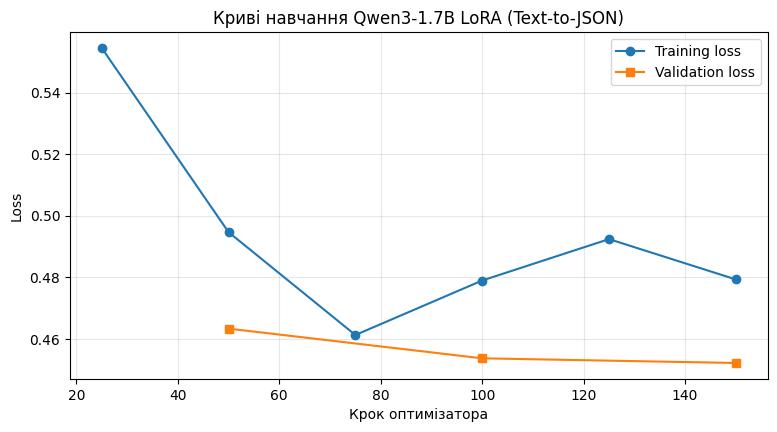

Інференс на тесті:   0%|          | 0/10 [00:00<?, ?it/s]

,До донавчання,Після донавчання
"JSON Syntax Rate, %",70.0,88.33
"Schema Compliance, %",68.0,86.00
"Canonical EM, %",0.0,0.00
Тестових прикладів,300.0,300.00


,Еталон,До донавчання,Схема ОК (до),Після донавчання,Схема ОК (після)
0,"{""games"": [{""age_range"": ""25-45"", ""duration"": ...","{\n ""games"": [\n {\n ""name"": ""Escape ...",True,"{""games"": [{""name"": ""Escape Room Challenge"", ""...",True
1,"{""globalStatistics"": {""countriesWithExecutions...","{\n ""globalStatistics"": {\n ""totalExecutio...",True,"{""globalStatistics"": {""totalExecutions"": 12345...",True
2,"{""optimal_route"": {""end_location"": ""San Franci...","{\n ""traffic_update"": {\n ""route_id"": ""R12...",True,"{""traffic_update"": {""route_id"": ""12345"", ""lati...",True
3,"{""countries"": [{""capital"": ""Ottawa"", ""name"": ""...","{\n ""countries"": [\n {\n ""name"": ""Uni...",True,"{""countries"": [{""name"": ""United States"", ""capi...",True
4,"[{""amino_acid_composition"": {""alanine"": 10, ""a...","[\n {\n ""protein_id"": ""protein1"",\n ""am...",True,"[{""protein_id"": ""P12345"", ""amino_acid_composit...",True
5,"{""confidence_interval"": [1350, 1550], ""predict...","{\n ""predicted_price"": 1250.0,\n ""confidence...",True,"{""predicted_price"": 1250, ""confidence_interval...",True
6,"{""compositionName"": ""Dance of the Elements"", ""...","{\n ""compositionName"": ""Interactive Dance Com...",False,"{""compositionName"": ""Dance Composition"", ""temp...",True


In [ ]:
history_rows = [
    {"step": entry["step"], "train_loss": entry.get("loss"), "val_loss": entry.get("eval_loss")}
    for entry in sft_trainer.state.log_history
    if "step" in entry and ("loss" in entry or "eval_loss" in entry)
]
metrics_history_df = pd.DataFrame(history_rows).groupby("step", as_index=False).last().sort_values("step")
display(metrics_history_df.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
tr_curve = metrics_history_df.dropna(subset=["train_loss"])
vl_curve = metrics_history_df.dropna(subset=["val_loss"])
ax.plot(tr_curve["step"], tr_curve["train_loss"], marker="o", label="Training loss")
ax.plot(vl_curve["step"], vl_curve["val_loss"], marker="s", label="Validation loss")
ax.set_xlabel("Крок оптимізатора")
ax.set_ylabel("Loss")
ax.set_title("Криві навчання Qwen3-1.7B LoRA (Text-to-JSON)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
sft_trainer.model.save_pretrained("qwen3_json_lora_adapter")
llm_model = sft_trainer.model.merge_and_unload()
llm_model.config.use_cache = True
llm_model.eval()

finetuned_metrics, finetuned_df = benchmark_on_split(llm_model, tokenizer, ds_test, EXTRACTION_SYSTEM_PROMPT)
display(pd.DataFrame({"До донавчання": baseline_metrics, "Після донавчання": finetuned_metrics}).round(2))

side_by_side_df = pd.DataFrame({
    "Еталон": baseline_df["reference"].head(7),
    "До донавчання": baseline_df["prediction"].head(7),
    "Схема ОК (до)": baseline_df["schema_ok"].head(7),
    "Після донавчання": finetuned_df["prediction"].head(7),
    "Схема ОК (після)": finetuned_df["schema_ok"].head(7),
})
display(side_by_side_df)

In [ ]:
def truncated_share(df):
    bad = df[~df["syntax_ok"]]
    if bad.empty:
        return 0, 0.0
    not_closed = ~bad["prediction"].str.rstrip().str.endswith(("}", "]", "```"))
    return len(bad), round(100 * not_closed.mean(), 1)

for name, df in [("До донавчання", baseline_df), ("Після донавчання", finetuned_df)]:
    n_bad, share = truncated_share(df)
    print(f"{name}: невалідних {n_bad}, з них без закриваючої дужки (імовірне обрізання): {share}%")


До донавчання: невалідних 90, з них без закриваючої дужки (імовірне обрізання): 90.0%
Після донавчання: невалідних 35, з них без закриваючої дужки (імовірне обрізання): 68.6%


### Результат після донавчання та аналіз помилок

**Результат на тесті (300 прикладів, ті самі приклади й налаштування генерації):**

| Метрика | До донавчання | Після донавчання | Зміна |
|---|---|---|---|
| JSON Syntax Rate | 70.00% | 88.33% | +18.33 в.п. |
| Schema Compliance | 68.00% | 86.00% | +18.00 в.п. |
| Canonical EM | 0.00% | 0.00% | = |

Невалідних відповідей стало 35 замість 90 (з 300). Похибка частки на 300 прикладах = приблизно ±4 в.п, тож приріст у ~18 в.п. істотний. Навчання: 150 кроків, 16.0 хв, пік VRAM 7.67 ГБ; validation loss 0.4634 → 0.4537 → 0.4522 (кроки 50/100/150), train loss ≈0.48, mean token accuracy на валідації 0.8711 → 0.8742; перенавчання немає.

**Про Canonical EM = 0.00.** Це метрика для задач з єдиним еталоном. Тут еталона в такому розумінні немає: response = один із багатьох допустимих JSON з вигаданими значеннями, а запит їх не містить. Нульовий EM не означає, що модель «не вміє точно», він лише показує, що метрика не застосовна до цієї постановки. Якість треба оцінювати за Syntax Rate і Schema Compliance.

**Звідки беруться помилки.** За евристикою «відповідь не закінчується на `}` чи `]`» (імовірне обрізання на ліміті 384 токени):

| | До | Після |
|---|---|---|
| Невалідний JSON (усього) | 90 | 35 |
| - з них імовірно обрізані | ≈81 (27% тесту) | ≈24 (8% тесту) |
| - інші синтаксичні помилки | ≈9 | ≈11 |
| Валідний JSON, але порушує схему | 6 | 7 |

Базова модель друкує JSON з відступами й переносами рядків, тож довгі відповіді обриваються на ліміті. Донавчена модель відтворює компактний формат навчальних відповідей і здебільшого вміщується в ліміт. **Приріст якості, отже, майже повністю пояснюється скороченням довжини, а не кращим дотриманням схеми:** кількість інших синтаксичних помилок не зменшилась. Це все одно корисний результат, але його варто описувати саме так.

**Помилки донавченої моделі:**
**Обрізані відповіді (≈24, ≈8% тесту)** - найдовші відповіді не вмістились у 384 токени. Це обмеження налаштувань генерації; у продакшені ліміт слід збільшити.

**Інші синтаксичні помилки (≈11, ≈4%)** - JSON не розбирається попри закриваючу дужку. Детально кожен випадок не розбирався.

**Порушення схеми (7, ≈2.3%)** - JSON валідний, але не відповідає схемі.

**Вигадування значень.** У прикладах із таблиці порівняння помітні шаблонні значення («12345», «P12345»). У ручному сценарії 3 (текст: «NovaTech Solutions is a fast-growing cloud startup based in Kyiv.», поля founded_year і ceo допускають null) модель вигадала founded_year: 2015 і CEO «Andriy Koval» замість null. Імовірна причина - у навчальних даних усі значення вигадані, тож модель навчилась «заповнювати» поля правдоподібними значеннями, а не залишати null, коли інформації немає. Для задачі витягування фактів це критична вада.

**Ручні сценарії (лише донавчена модель):** 3 із 4 дали точний збіг з еталоном (прості типи; вкладені об'єкти та масиви; структура замовлення). Сценарій 3 (відсутні поля) - невдача через вигадування значень.

**Загальні запити поза задачею (5 запитів, «до → після»):**
17 × 24: правильно в обох випадках (відповідь стала коротшою).

Переклад українською: до - неякісний, але переклад («Сімейна розмовка відбудеться завтра раніше»); після - англійське речення повернуто без перекладу. **Регресія.**

«Три назви кольорів через кому»: однаково (red,blue,green).

Різниця list/tuple у двох реченнях: відповідь по суті правильна й до, і після.

Функція is_even: до - код у кілька рядків, після - в один рядок (def is_even(n): return n % 2 == 0); коректно, але стиль став компактнішим.

Вибірка з п'яти запитів лише ілюстративна, статистичних висновків робити не можна. Але помітний зсув до компактного формату та регресія в перекладі показують, що адаптер впливає й на поведінку поза задачею.

In [ ]:
MANUAL_SCENARIOS = [
    {
        "case": "Базове витягування типів (рядок, число, булеве)",
        "schema": json.dumps({
            "type": "object",
            "properties": {
                "product_name": {"type": "string"},
                "price": {"type": "number"},
                "in_stock": {"type": "boolean"}
            },
            "required": ["product_name", "price", "in_stock"]
        }),
        "text": "The new wireless mechanical keyboard Keychron K2 costs 89.99 dollars and is currently available in our warehouse.",
        "reference": '{"product_name": "Keychron K2", "price": 89.99, "in_stock": true}'
    },
    {
        "case": "Вкладені об'єкти та масиви",
        "schema": json.dumps({
            "type": "object",
            "properties": {
                "patient": {"type": "string"},
                "symptoms": {"type": "array", "items": {"type": "string"}},
                "urgent": {"type": "boolean"}
            },
            "required": ["patient", "symptoms", "urgent"]
        }),
        "text": "Patient Olena Kovalenko complains of severe headache, fever, and dry cough since yesterday. Immediate doctor visit is not required.",
        "reference": '{"patient": "Olena Kovalenko", "symptoms": ["severe headache", "fever", "dry cough"], "urgent": false}'
    },
    {
        "case": "Обробка відсутніх полів (null / опціональні поля)",
        "schema": json.dumps({
            "type": "object",
            "properties": {
                "company": {"type": "string"},
                "founded_year": {"type": ["integer", "null"]},
                "ceo": {"type": ["string", "null"]}
            },
            "required": ["company", "founded_year", "ceo"]
        }),
        "text": "NovaTech Solutions is a fast-growing cloud startup based in Kyiv.",
        "reference": '{"company": "NovaTech Solutions", "founded_year": null, "ceo": null}'
    },
    {
        "case": "Складна вкладена структура замовлення",
        "schema": json.dumps({
            "type": "object",
            "properties": {
                "order_id": {"type": "integer"},
                "items": {
                    "type": "array",
                    "items": {
                        "type": "object",
                        "properties": {
                            "sku": {"type": "string"},
                            "qty": {"type": "integer"}
                        },
                        "required": ["sku", "qty"]
                    }
                }
            },
            "required": ["order_id", "items"]
        }),
        "text": "Order #1045 contains 2 units of item MON-27 and 1 unit of CAB-HDMI.",
        "reference": '{"order_id": 1045, "items": [{"sku": "MON-27", "qty": 2}, {"sku": "CAB-HDMI", "qty": 1}]}'
    }
]

scenario_prompts = [f"JSON Schema:\n{s['schema']}\n\nText:\n{s['text']}" for s in MANUAL_SCENARIOS]
scenario_outputs = run_batch_inference(llm_model, tokenizer, scenario_prompts, EXTRACTION_SYSTEM_PROMPT)

for idx, (sc, out) in enumerate(zip(MANUAL_SCENARIOS, scenario_outputs), 1):
    print(f"\n=== Сценарій {idx}: {sc['case']} ===")
    print("Відповідь моделі:", out)
    print("Еталон:          ", sc["reference"])
    validated_out = canonicalize_if_valid(out, sc["schema"])
    validated_ref = canonicalize_if_valid(sc["reference"], sc["schema"])
    print("Валідний за схемою:", validated_out is not None)
    print("Точний збіг:       ", validated_out == validated_ref)


=== Сценарій 1: Базове витягування типів (рядок, число, булеве) ===
Відповідь моделі: {"product_name": "Keychron K2", "price": 89.99, "in_stock": true}
Еталон:           {"product_name": "Keychron K2", "price": 89.99, "in_stock": true}
Валідний за схемою: True
Точний збіг:        True

=== Сценарій 2: Вкладені об'єкти та масиви ===
Відповідь моделі: {"patient": "Olena Kovalenko", "symptoms": ["severe headache", "fever", "dry cough"], "urgent": false}
Еталон:           {"patient": "Olena Kovalenko", "symptoms": ["severe headache", "fever", "dry cough"], "urgent": false}
Валідний за схемою: True
Точний збіг:        True

=== Сценарій 3: Обробка відсутніх полів (null / опціональні поля) ===
Відповідь моделі: {"company": "NovaTech Solutions", "founded_year": 2015, "ceo": "Andriy Koval"}
Еталон:           {"company": "NovaTech Solutions", "founded_year": null, "ceo": null}
Валідний за схемою: True
Точний збіг:        False

=== Сценарій 4: Складна вкладена структура замовлення ===
Відповід

In [ ]:
tuned_general_answers = run_batch_inference(llm_model, tokenizer, general_queries, DEFAULT_ASSISTANT_PROMPT, max_tokens=200)

for query, ans_base, ans_tuned in zip(general_queries, base_general_answers, tuned_general_answers):
    print(f"\nЗАПИТ: {query}\nДО:    {ans_base}\nПІСЛЯ: {ans_tuned}")



ЗАПИТ: Calculate 17 multiplied by 24.
ДО:    17 multiplied by 24 is 408.
ПІСЛЯ: 17 * 24 = 408

ЗАПИТ: Translate into Ukrainian: 'The meeting will take place tomorrow morning.'
ДО:    Сімейна розмовка відбудеться завтра раніше.
ПІСЛЯ: The meeting will take place tomorrow morning.

ЗАПИТ: Return exactly three color names, separated by commas, without any other text.
ДО:    red,blue,green
ПІСЛЯ: red,blue,green

ЗАПИТ: Explain the difference between a Python list and a Python tuple in two sentences.
ДО:    A Python list is a dynamic, mutable sequence of elements that can be modified after creation, while a Python tuple is a static, immutable sequence that cannot be changed once created.
ПІСЛЯ: A Python list is a dynamic data structure that allows for efficient insertion and deletion of elements, while a Python tuple is a read-only data structure that is more memory-efficient and faster to access.

ЗАПИТ: Write a Python function is_even(n) that returns True for even integers and False for 

### Висновок

LoRA-донавчання (≈1% параметрів, 150 кроків, 16.0 хв і 7.67 ГБ VRAM на T4) підняло частку відповідей, що проходять валідацію за JSON-схемою, з 68.00% до 86.00%, а частку синтаксично коректних JSON - з 70.00% до 88.33%. Цільових 100% не досягнуто: 35 з 300 відповідей лишаються невалідними.

Аналіз помилок показує, що приріст майже повністю дає скорочення довжини відповідей: базова модель друкує JSON з відступами й часто обривається на ліміті 384 токени (≈81 із 90 невалідних відповідей), донавчена видає компактний JSON (≈24 із 35). Інші синтаксичні помилки не зменшились (≈9 → ≈11). Метрика Canonical EM = 0.00 в обох випадках, бо в цій постановці немає єдиного еталона, тому вона неінформативна.

**Обмеження:** датасет синтетичний, англомовний, з вигаданими значеннями, тож модель навчилась заповнювати поля правдоподібними даними й вигадує значення навіть там, де їх немає в запиті. Для достовірного витягування фактів з тексту вона не підходить. Крім того, є легка регресія поза задачею і зсув до компактного стилю відповідей. Перевірка збігу схем між train і test не проводилась, тож частину результату може пояснювати знайомство з типовими схемами.

**Що можна покращити:** збільшити max_new_tokens або обмежити декодування схемою, щоб прибрати обрізання; додати в навчання приклади з реальним текстом і null для відсутніх полів та оцінювати точність по полях; додати в навчання частку загальних інструкцій, щоб зменшити регресію.

## 1.6. Мій звіт

### Задача і чому потрібне донавчання
Генерація структурованого JSON за JSON-схемою: на вхід - схема й короткий англомовний запит, на виході - лише JSON, що проходить валідацію за схемою. Користувач - бекенд-розробник, якому наступна ланка конвеєра потребує машинозчитуваної відповіді. Базова Qwen3-1.7B навіть з явною інструкцією в системному промпті дає JSON, що проходить валідацію, лише у 68% випадків, переважно через багатослівне форматування, яке призводить до обриву відповіді на ліміті довжини. Промпт цього не усунув, а LoRA-донавчання змінює сам стиль відповіді. RAG не підходить: уся потрібна інформація уже є у вході, зовнішні факти не потрібні.

### Модель і дані
**Модель:** Qwen/Qwen3-1.7B (post-trained версія, режим міркування вимкнено), fp16; 1.7 млрд параметрів комфортно поміщаються в T4, а інструктивна версія дозволяє чесно виміряти базову здатність слідувати схемі за промптом.
**Дані:** [ChristianAzinn/json-training](https://huggingface.co/datasets/ChristianAzinn/json-training), Apache 2.0, 20 644 синтетичні англомовні записи (query, schema, response; згенеровані переважно Llama 3.1 8B, ≈2000 - Claude 3.5 Sonnet). Після видалення дублікатів і перевірки валідності відібрано 3 500; поділ: train 2 395 (після відсікання >1024 токенів), validation 300 (у навчанні використано 100), test 300, без перетину. Приклади - у виводі клітинки із завантаженням датасету.
**Обмеження датасету:** значення в response вигадані, запит не містить тексту для витягування, тому це генерація за схемою, а не витягування фактів.

### Метрика й результат до донавчання
**Метрики:** JSON Syntax Rate (парситься json.loads), **Schema Compliance** (проходить валідацію за схемою; головна, бо саме її вимагає наступна ланка конвеєра) і Canonical EM (допоміжна). BLEU/ROUGE не підходять, бо порядок ключів і пробіли не впливають на валідність, а одна зайва кома ламає парсер. Canonical EM у цій постановці неінформативна: еталон - один із багатьох допустимих JSON з вигаданими значеннями.
До донавчання (300 прикладів, системний промпт з вимогою лише JSON, жадібне декодування, max_new_tokens=384): Syntax 70.00%, Schema 68.00%, EM 0.00%. Сім прикладів відповідей наведено у таблиці порівняння; базова модель друкує JSON з відступами, 90 із 300 відповідей невалідні.

### Метод донавчання й гіперпараметри
SFT з LoRA (r=16, lora_alpha=32, dropout 0.05, all-linear; 17.4 млн параметрів, ≈1.0%), assistant_only_loss=True. Learning rate 1e-4, косинусне затухання, weight decay 0.01, clip 1.0; 1 епоха = 150 кроків; ефективний батч 16 (1×16), max_length=1024, fp16, gradient checkpointing вимкнено; оцінка кожні 50 кроків із вибором найкращого чекпоінта.
Тривалість: 16.0 хв. Пікова VRAM: 7.67 ГБ. **Loss:** train ≈0.55 (крок 25) → ≈0.48; validation 0.4634 → 0.4537 → 0.4522 (кроки 50/100/150). Перенавчання немає.
У пробному прогоні з 2 епохами (300 кроків, 50.9 хв, пік 4.4 ГБ з checkpointing) validation loss майже не змінювався після ~150-го кроку (0.4840 → 0.4813), тому для економії часу залишено 1 епоху.

### Результат після донавчання
На тих самих 300 прикладах: Syntax 70.00% → 88.33%, Schema Compliance 68.00% → 86.00%, EM 0.00% → 0.00%. Невалідних відповідей 90 → 35. Похибка ≈±4 в.п., тож приріст істотний. Цільових 100% не досягнуто.

### Аналіз помилок
За евристикою «відповідь не закінчується на `}`/`]`» з 90 невалідних відповідей базової моделі ≈81 імовірно обрізані на ліміті 384 токени, у донавченої - ≈24 із 35. Інші синтаксичні помилки не зменшились (≈9 → ≈11), тож приріст майже повністю дає скорочення довжини (компактний JSON), а не краще дотримання схеми.

У донавченої моделі: ≈24 обрізані відповіді (8%), ≈11 інших синтаксичних помилок (4%), 7 валідних JSON, що порушують схему (2.3%).

Вигадування значень: у зразках шаблонні «12345»/«P12345»; у ручному сценарії 3 модель вигадала founded_year: 2015 і CEO замість null. Імовірна причина - у навчальних даних усі значення вигадані. Ручні сценарії: 3 із 4 точно.

Загальні запити (5): регресія в перекладі, код став компактнішим; арифметика, список кольорів і пояснення list/tuple без втрат. Вибірка лише ілюстративна.

### Висновок
LoRA-донавчання за 16 хв на T4 підняло Schema Compliance з 68.0% до 86.0%, але переважно завдяки компактному формату, що вміщується в ліміт довжини; цільових 100% не досягнуто. Через синтетичні дані з вигаданими значеннями модель вигадує поля навіть там, де інформації немає, тож для достовірного витягування фактів вона не підходить, а для генерації за схемою потребує валідації виходу.

 https://huggingface.co/Bloody03/qwen3-1.7b-json-schema-lora (Адаптер)